# Import Library

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
%matplotlib inline
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# LOAD DATASET

In [2]:
df = pd.read_csv("student_performance_dataset.csv")

In [4]:
df.head()

,student_id,study_hours_per_week,attendance_percentage,sleep_hours_per_night,previous_gpa_4_scale,internet_access,extracurricular_participation,final_exam_score,grade
0,STU001,11.9,75.3,7.1,3.47,Yes,No,100.0,A
1,STU002,13.1,99.8,6.3,2.43,Yes,No,87.2,A
2,STU003,12.9,66.6,7.0,1.86,No,No,95.0,A
3,STU004,11.5,75.2,5.8,2.51,Yes,Yes,85.6,A
4,STU005,15.8,85.9,10.0,2.93,Yes,No,100.0,A


In [4]:
df.shape

(200, 9)

In [5]:
df = pd.read_csv("student_performance_dataset.csv")

numeric = [
    "study_hours_per_week",
    "attendance_percentage",
    "sleep_hours_per_night",
    "previous_gpa_4_scale",
    "final_exam_score"
]

categorical = [
    "internet_access",
    "extracurricular_participation",
    "grade"
]

In [6]:
df.head()

,student_id,study_hours_per_week,attendance_percentage,sleep_hours_per_night,previous_gpa_4_scale,internet_access,extracurricular_participation,final_exam_score,grade
0,STU001,11.9,75.3,7.1,3.47,Yes,No,100.0,A
1,STU002,13.1,99.8,6.3,2.43,Yes,No,87.2,A
2,STU003,12.9,66.6,7.0,1.86,No,No,95.0,A
3,STU004,11.5,75.2,5.8,2.51,Yes,Yes,85.6,A
4,STU005,15.8,85.9,10.0,2.93,Yes,No,100.0,A


# Exploratory Data Analysis

# Check Missing values

In [7]:
df.isna().sum()

student_id                       0
study_hours_per_week             0
attendance_percentage            0
sleep_hours_per_night            0
previous_gpa_4_scale             0
internet_access                  0
extracurricular_participation    0
final_exam_score                 0
grade                            0
dtype: int64

# Check Duplicates

In [8]:
df.duplicated().sum()

np.int64(0)

# Check data types

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   student_id                     200 non-null    str    
 1   study_hours_per_week           200 non-null    float64
 2   attendance_percentage          200 non-null    float64
 3   sleep_hours_per_night          200 non-null    float64
 4   previous_gpa_4_scale           200 non-null    float64
 5   internet_access                200 non-null    str    
 6   extracurricular_participation  200 non-null    str    
 7   final_exam_score               200 non-null    float64
 8   grade                          200 non-null    str    
dtypes: float64(5), str(4)
memory usage: 16.6 KB


# Checking the number of unique values of each column

In [10]:
df.nunique()

student_id                       200
study_hours_per_week             114
attendance_percentage            161
sleep_hours_per_night             45
previous_gpa_4_scale             114
internet_access                    2
extracurricular_participation      2
final_exam_score                 119
grade                              3
dtype: int64

# DATA OVERVIEW

In [11]:
print("\n========== DATA OVERVIEW ==========")

print("\nFirst 5 Rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())



========== DATA OVERVIEW ==========

First 5 Rows:
  student_id  study_hours_per_week  attendance_percentage  \
0     STU001                  11.9                   75.3   
1     STU002                  13.1                   99.8   
2     STU003                  12.9                   66.6   
3     STU004                  11.5                   75.2   
4     STU005                  15.8                   85.9   

   sleep_hours_per_night  previous_gpa_4_scale internet_access  \
0                    7.1                  3.47             Yes   
1                    6.3                  2.43             Yes   
2                    7.0                  1.86              No   
3                    5.8                  2.51             Yes   
4                   10.0                  2.93             Yes   

  extracurricular_participation  final_exam_score grade  
0                            No             100.0     A  
1                            No              87.2     A  
2         

# Correlation Matrix

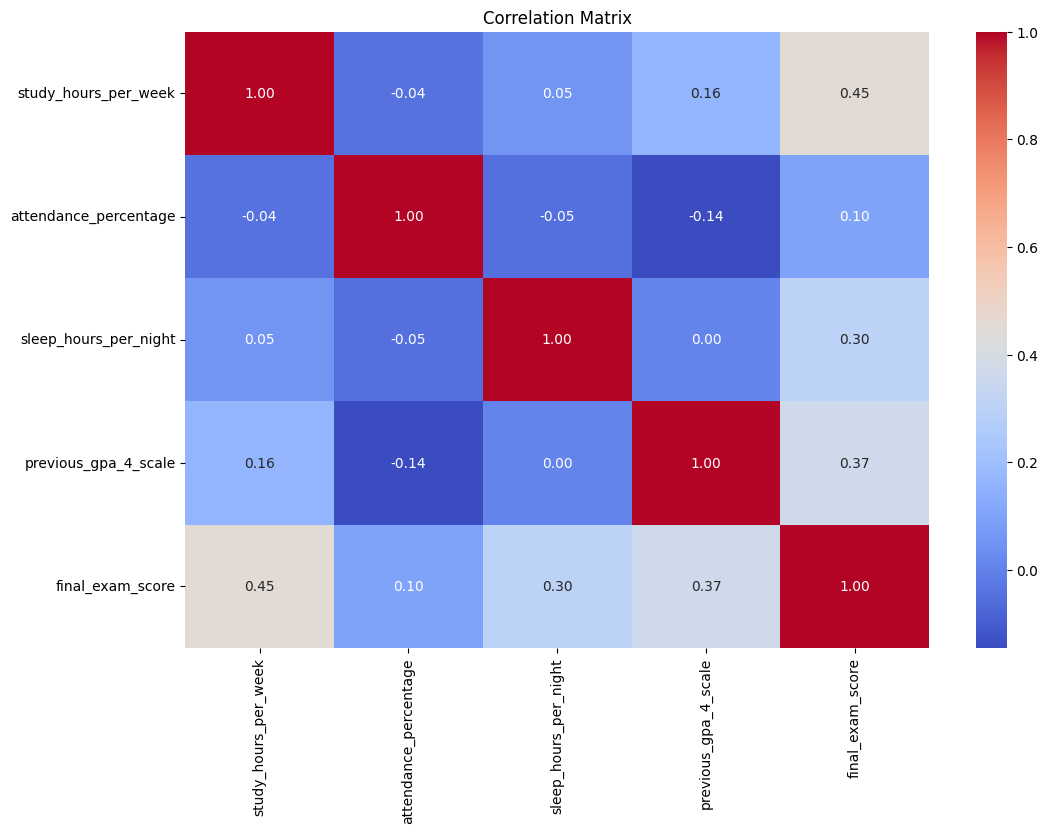

In [12]:
plt.figure(figsize=(12,8))
corr = df.corr(numeric_only=True)

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

# Constructing a heatmap to understand the correlation between the columns

<Axes: >

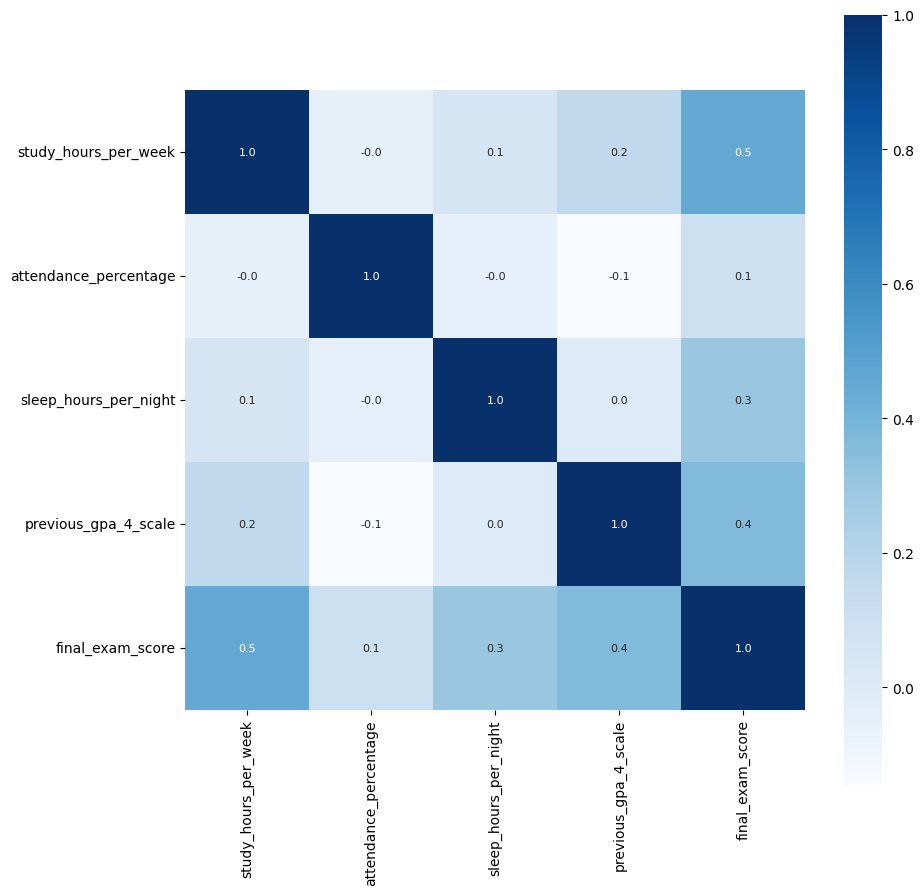

In [13]:
plt.figure(figsize=(10,10))
sns.heatmap(corr, cbar=True, square=True, fmt = '.1f', annot = True, annot_kws={'size':8}, cmap = 'Blues')

# Correlation
- Positive Correlation
- Negative Correlation

# Distribution of Features

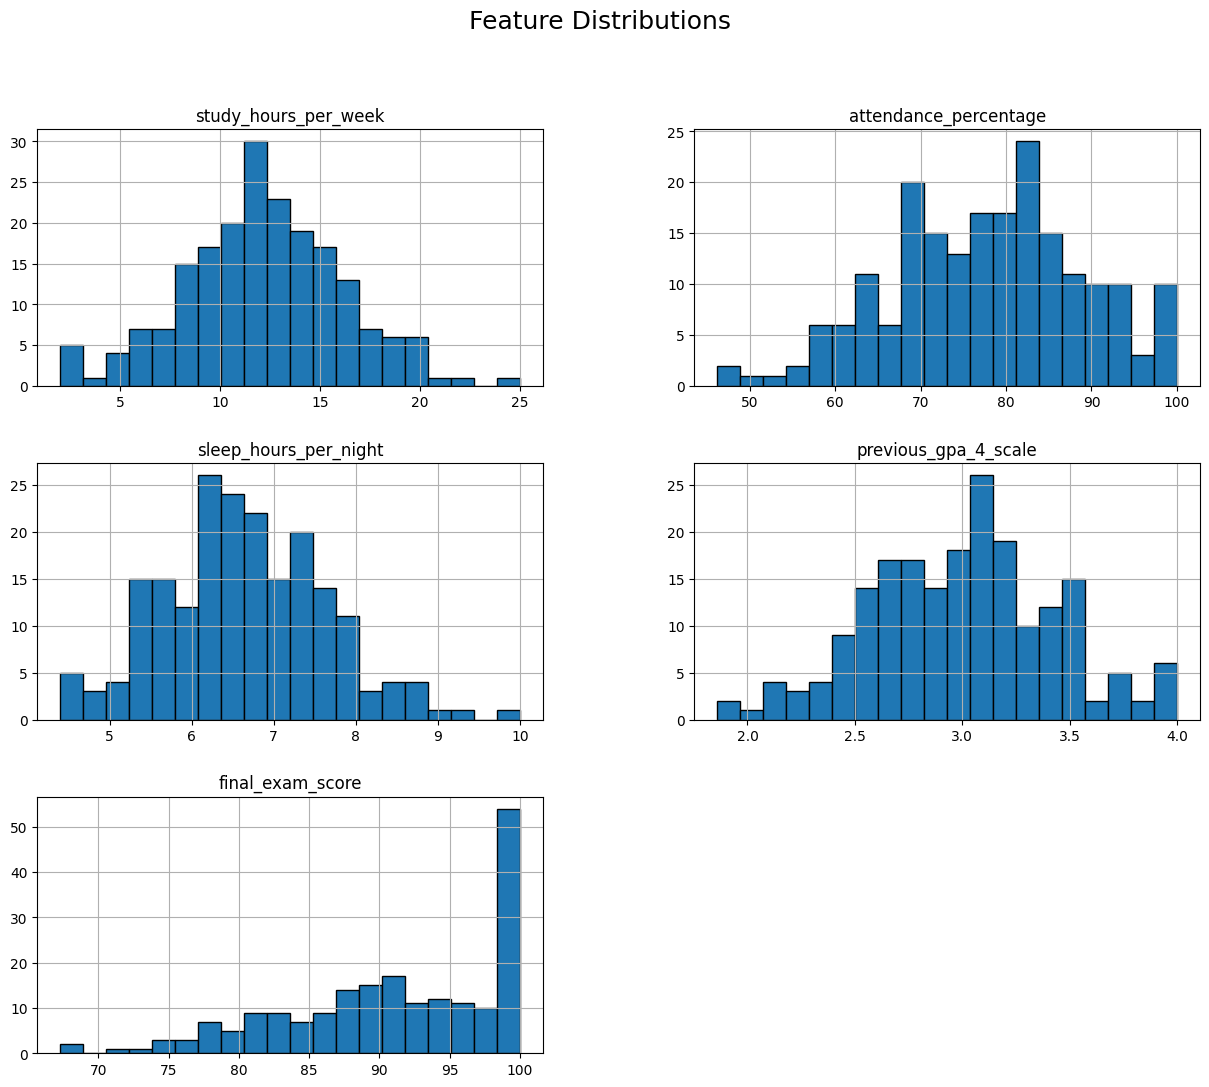

In [14]:
df.hist(
    figsize=(15,12),
    bins=20,
    edgecolor='black'
)

plt.suptitle("Feature Distributions", fontsize=18)
plt.show()


# Boxplots for Outlier Detection

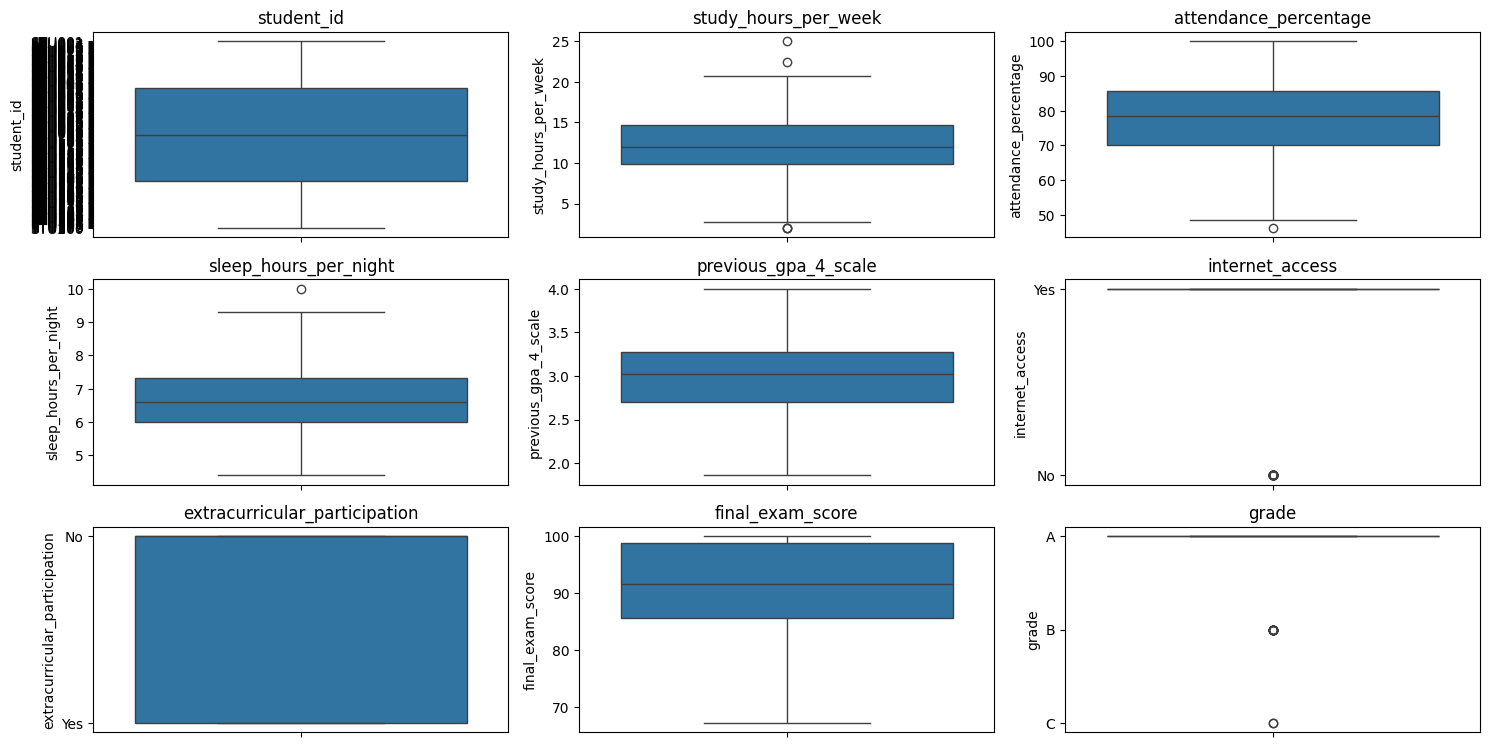

In [15]:
plt.figure(figsize=(15,10))

for i, column in enumerate(df.columns, 1):
    plt.subplot(4, 3, i)
    sns.boxplot(y=df[column])
    plt.title(column)

plt.tight_layout()
plt.show()

Little outliers present here. Remove outlier from the dataset.

# Skewness Check


========== FEATURE SKEWNESS ==========
study_hours_per_week     0.0065
attendance_percentage   -0.1542
sleep_hours_per_night    0.2750
previous_gpa_4_scale     0.0164
final_exam_score        -0.6442
dtype: float64

Skewness Interpretation:
                       Skewness                               Interpretation
study_hours_per_week   0.006515  Approximately Symmetric / Slightly Positive
attendance_percentage -0.154166                   Slightly Negatively Skewed
sleep_hours_per_night  0.275014  Approximately Symmetric / Slightly Positive
previous_gpa_4_scale   0.016439  Approximately Symmetric / Slightly Positive
final_exam_score      -0.644218                 Moderately Negatively Skewed


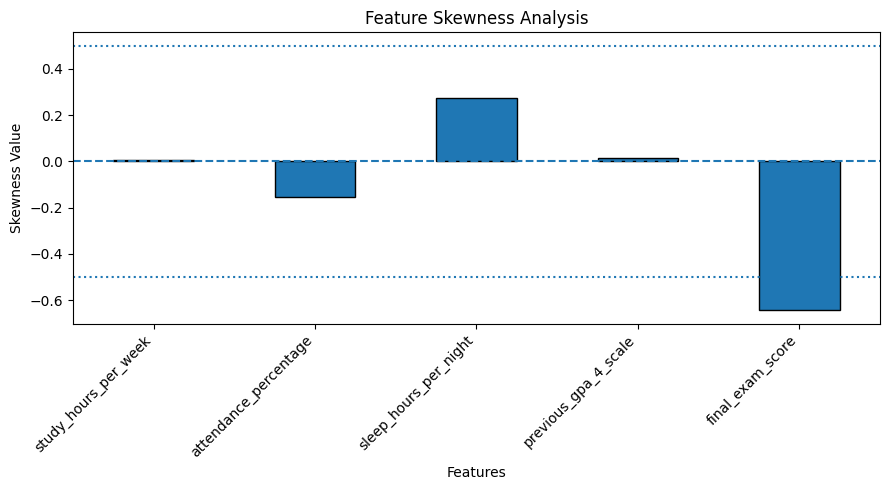

In [17]:

# Feature Skewness Analysis

print("\n========== FEATURE SKEWNESS ==========")

skewness = df[numeric].skew()

print(skewness.round(4))


# Interpret Skewness

def interpret_skewness(value):

    if value < -1:
        return "Highly Negatively Skewed"

    elif value < -0.5:
        return "Moderately Negatively Skewed"

    elif value < 0:
        return "Slightly Negatively Skewed"

    elif value <= 0.5:
        return "Approximately Symmetric / Slightly Positive"

    elif value <= 1:
        return "Moderately Positively Skewed"

    else:
        return "Highly Positively Skewed"


skewness_analysis = pd.DataFrame({

    "Skewness": skewness,

    "Interpretation": skewness.apply(
        interpret_skewness
    )

})

print("\nSkewness Interpretation:")

print(skewness_analysis)


# Save Results

skewness_analysis.to_csv(
    "skewness_analysis.csv"
)


# Visualize Skewness

plt.figure(figsize=(9, 5))

skewness.plot(
    kind="bar",
    edgecolor="black"
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.axhline(
    y=0.5,
    linestyle=":"
)

plt.axhline(
    y=-0.5,
    linestyle=":"
)

plt.xlabel("Features")

plt.ylabel("Skewness Value")

plt.title("Feature Skewness Analysis")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig(
    "feature_skewness.png",
    dpi=180
)

plt.show()


In [18]:
print("\nFeature Skewness:")
print(df.skew(numeric_only=True))


Feature Skewness:
study_hours_per_week     0.006515
attendance_percentage   -0.154166
sleep_hours_per_night    0.275014
previous_gpa_4_scale     0.016439
final_exam_score        -0.644218
dtype: float64


# Feature Skewness Analysis
The skewness analysis indicates that most numerical features in the Student Academic Performance dataset are approximately symmetrically distributed.

Study hours per week (0.0065) and previous GPA (0.0164) exhibit almost perfectly symmetric distributions. Attendance percentage (-0.1542) shows slight negative skewness, while sleep hours per night (0.2750) demonstrates slight positive skewness.

However, final exam scores (-0.6442) exhibit moderate negative skewness, indicating that scores are concentrated toward higher values, with a relatively small number of students obtaining lower scores.

Overall, the dataset does not show substantial skewness in most numerical features. The final exam score deserves additional investigation through a histogram and boxplot to understand its distribution and identify potential outliers.


# Outlier Detection using IQR

In [19]:
Q1 = df.quantile(0.25, numeric_only=True)
Q3 = df.quantile(0.75, numeric_only=True)

IQR = Q3 - Q1

# Filter DataFrame to only numeric columns before calculating outliers
df_numeric = df[numeric]
outliers = ((df_numeric < (Q1 - 1.5 * IQR)) |
            (df_numeric > (Q3 + 1.5 * IQR)))

print("\nOutliers per Feature:")
print(outliers.sum())


Outliers per Feature:
study_hours_per_week     5
attendance_percentage    1
sleep_hours_per_night    1
previous_gpa_4_scale     0
final_exam_score         0
dtype: int64


# The IQR analysis shows that:
- Several features contain significant outliers.
- Proper preprocessing is important before machine learning.
- Outlier handling can improve model stability and prediction performance.

# Remove Outliers using IQR Method

In [20]:
# Calculate Q1 and Q3
Q1 = df.quantile(0.25, numeric_only=True)
Q3 = df.quantile(0.75, numeric_only=True)

# Calculate IQR
IQR = Q3 - Q1

# Remove outliers based on numeric columns only
df_no_outliers = df[
    ~((df[numeric] < (Q1 - 1.5 * IQR)) |
      (df[numeric] > (Q3 + 1.5 * IQR))).any(axis=1)
]

# Shape before and after
print("Original Shape:", df.shape)
print("Shape After Removing Outliers:", df_no_outliers.shape)

# Optional: Replace original dataframe
df = df_no_outliers



Original Shape: (200, 9)
Shape After Removing Outliers: (193, 9)


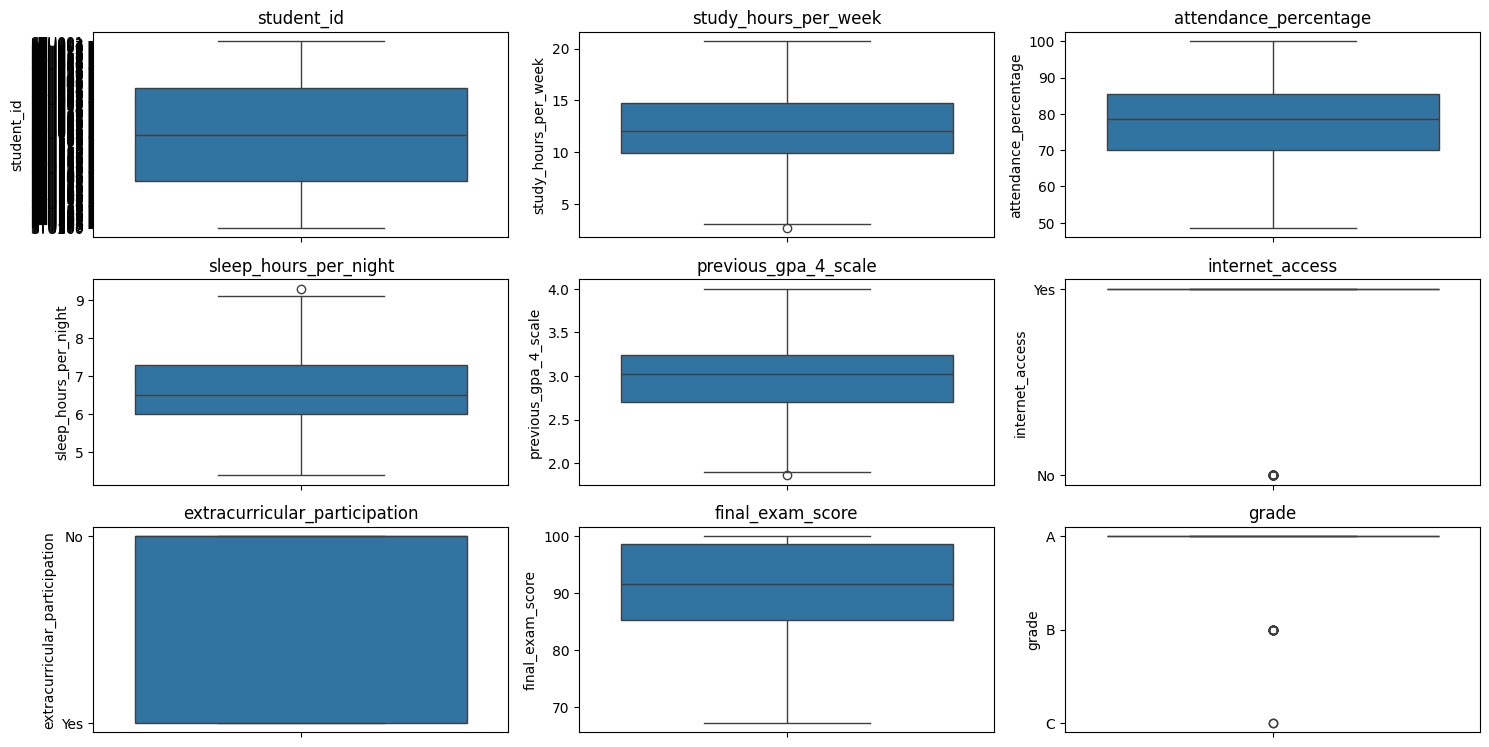

In [21]:
plt.figure(figsize=(15,10))

for i, column in enumerate(df.columns, 1):
    plt.subplot(4, 3, i)
    sns.boxplot(y=df[column])
    plt.title(column)

plt.tight_layout()
plt.show()

# Range Analysis

In [41]:

# Calculate minimum, maximum and range

range_analysis = pd.DataFrame({
    'Minimum': df[numerical_cols].min(),
    'Maximum': df[numerical_cols].max(),
    'Range': df[numerical_cols].max() - df[numerical_cols].min()
})

print("Range Analysis:")
print(range_analysis.round(2))


Range Analysis:
                       Minimum  Maximum  Range
study_hours_per_week      2.00     25.0  23.00
attendance_percentage    46.20    100.0  53.80
sleep_hours_per_night     4.40     10.0   5.60
previous_gpa_4_scale      1.86      4.0   2.14
final_exam_score         67.30    100.0  32.70


In [42]:

# Calculate Q1 and Q3
Q1 = df[numerical_cols].quantile(0.25)
Q3 = df[numerical_cols].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate lower and upper bounds
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

# Create outlier summary
outlier_summary = pd.DataFrame({
    'Q1': Q1,
    'Q3': Q3,
    'IQR': IQR,
    'Lower Bound': lower_bound,
    'Upper Bound': upper_bound
})

print("IQR Analysis:")
print(outlier_summary.round(2))


IQR Analysis:
                          Q1     Q3    IQR  Lower Bound  Upper Bound
study_hours_per_week    9.88  14.70   4.82         2.64        21.94
attendance_percentage  70.00  85.52  15.53        46.71       108.81
sleep_hours_per_night   6.00   7.32   1.33         4.01         9.31
previous_gpa_4_scale    2.70   3.27   0.57         1.85         4.12
final_exam_score       85.60  98.72  13.12        65.91       118.41


In [43]:

# Count outliers
outlier_count = {}

for col in numerical_cols:

    lower = lower_bound[col]
    upper = upper_bound[col]

    outliers = df[
        (df[col] < lower) | (df[col] > upper)
    ]

    outlier_count[col] = len(outliers)

# Display results
outlier_result = pd.DataFrame(
    list(outlier_count.items()),
    columns=['Variable', 'Outlier Count']
)

print(outlier_result)


                Variable  Outlier Count
0   study_hours_per_week              5
1  attendance_percentage              1
2  sleep_hours_per_night              1
3   previous_gpa_4_scale              0
4       final_exam_score              0


In [44]:

for col in numerical_cols:

    outliers = df[
        (df[col] < lower_bound[col]) |
        (df[col] > upper_bound[col])
    ]

    print(f"\nOutliers in {col}:")
    print(outliers[['student_id', col]])



Outliers in study_hours_per_week:
    student_id  study_hours_per_week
5       STU006                   2.0
28      STU029                   2.0
101     STU102                   2.0
120     STU121                  22.5
155     STU156                  25.0

Outliers in attendance_percentage:
   student_id  attendance_percentage
12     STU013                   46.2

Outliers in sleep_hours_per_night:
  student_id  sleep_hours_per_night
4     STU005                   10.0

Outliers in previous_gpa_4_scale:
Empty DataFrame
Columns: [student_id, previous_gpa_4_scale]
Index: []

Outliers in final_exam_score:
Empty DataFrame
Columns: [student_id, final_exam_score]
Index: []


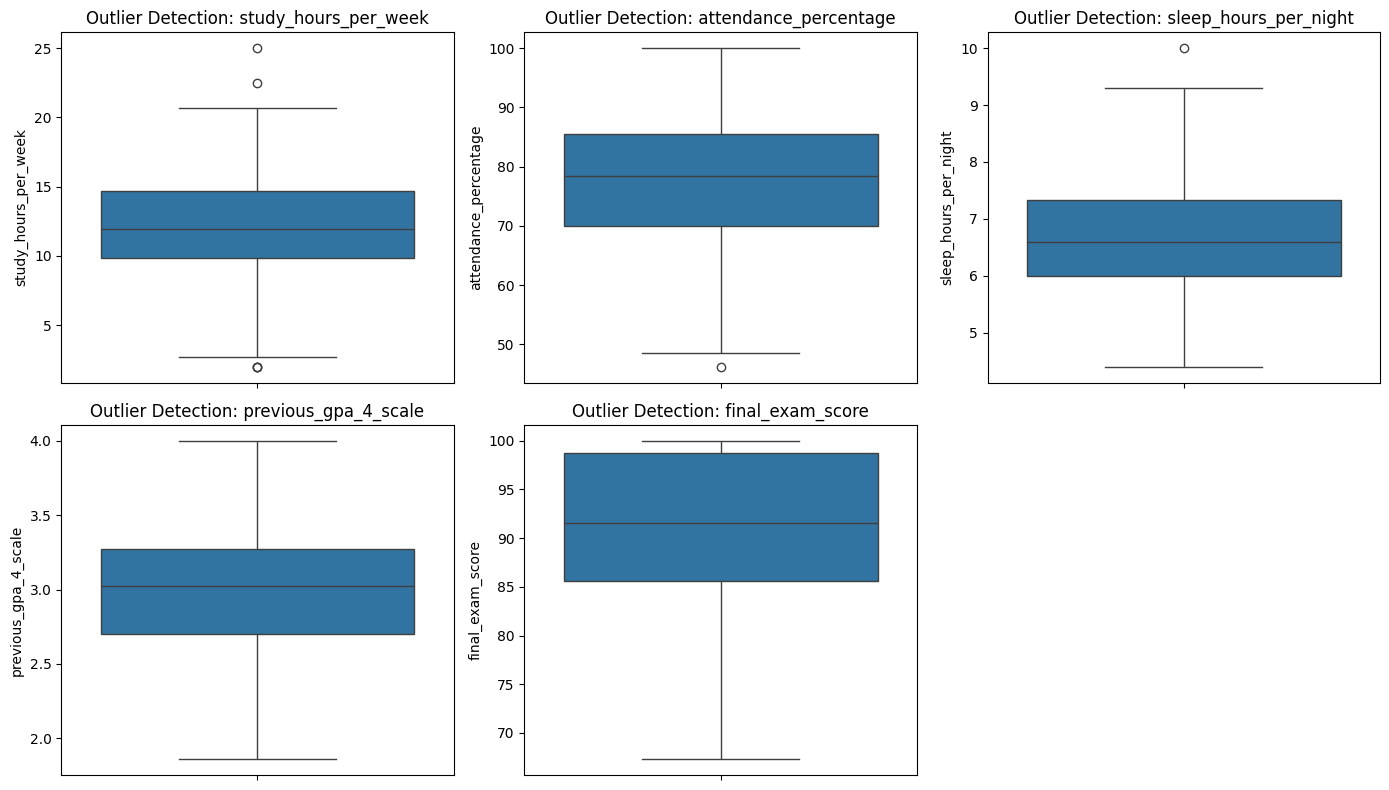

In [45]:

plt.figure(figsize=(14, 8))

for i, col in enumerate(numerical_cols, 1):

    plt.subplot(2, 3, i)

    sns.boxplot(y=df[col])

    plt.title(f'Outlier Detection: {col}')
    plt.ylabel(col)

plt.tight_layout()
plt.show()


Successfully remove outliers from the dataset.

# DESCRIPTIVE STATISTICS

In [22]:
print("\n========== DESCRIPTIVE STATISTICS ==========")

print(df[numeric].describe().T.round(2))

print("\nAdditional Statistics:")

for col in numeric:

    print(f"\n{col}")

    print("Mean:", round(df[col].mean(), 2))
    print("Median:", round(df[col].median(), 2))
    print("Mode:", round(df[col].mode()[0], 2))
    print("Standard Deviation:", round(df[col].std(), 2))
    print("Variance:", round(df[col].var(), 2))
    print("Minimum:", round(df[col].min(), 2))
    print("Maximum:", round(df[col].max(), 2))


========== DESCRIPTIVE STATISTICS ==========
                       count   mean    std    min   25%    50%    75%    max
study_hours_per_week   193.0  12.19   3.68   2.70   9.9  12.00  14.70   20.7
attendance_percentage  193.0  78.13  11.12  48.60  70.0  78.60  85.50  100.0
sleep_hours_per_night  193.0   6.63   0.96   4.40   6.0   6.50   7.30    9.3
previous_gpa_4_scale   193.0   2.98   0.43   1.86   2.7   3.02   3.24    4.0
final_exam_score       193.0  90.98   7.89  67.30  85.4  91.60  98.70  100.0

Additional Statistics:

study_hours_per_week
Mean: 12.19
Median: 12.0
Mode: 10.6
Standard Deviation: 3.68
Variance: 13.51
Minimum: 2.7
Maximum: 20.7

attendance_percentage
Mean: 78.13
Median: 78.6
Mode: 100.0
Standard Deviation: 11.12
Variance: 123.58
Minimum: 48.6
Maximum: 100.0

sleep_hours_per_night
Mean: 6.63
Median: 6.5
Mode: 6.4
Standard Deviation: 0.96
Variance: 0.92
Minimum: 4.4
Maximum: 9.3

previous_gpa_4_scale
Mean: 2.98
Median: 3.02
Mode: 2.72
Standard Deviation: 0.43
Varian

In [23]:
df.head()

,student_id,study_hours_per_week,attendance_percentage,sleep_hours_per_night,previous_gpa_4_scale,internet_access,extracurricular_participation,final_exam_score,grade
0,STU001,11.9,75.3,7.1,3.47,Yes,No,100.0,A
1,STU002,13.1,99.8,6.3,2.43,Yes,No,87.2,A
2,STU003,12.9,66.6,7.0,1.86,No,No,95.0,A
3,STU004,11.5,75.2,5.8,2.51,Yes,Yes,85.6,A
6,STU007,11.8,81.3,5.4,2.47,No,No,90.8,A


In [24]:
df.describe()

,study_hours_per_week,attendance_percentage,sleep_hours_per_night,previous_gpa_4_scale,final_exam_score
count,193.000000,193.000000,193.000000,193.000000,193.000000
mean,12.190674,78.127461,6.628497,2.983627,90.984456
std,3.675257,11.116632,0.959528,0.426316,7.890848
min,2.700000,48.600000,4.400000,1.860000,67.300000
25%,9.900000,70.000000,6.000000,2.700000,85.400000
50%,12.000000,78.600000,6.500000,3.020000,91.600000
75%,14.700000,85.500000,7.300000,3.240000,98.700000
max,20.700000,100.000000,9.300000,4.000000,100.000000


# CATEGORICAL DATA ANALYSIS

In [26]:
print("\n========== CATEGORICAL ANALYSIS ==========")

for col in categorical:

    print(f"\nFrequency Distribution: {col}")

    print(df[col].value_counts())

    print("\nPercentage Distribution:")

    print(
        (df[col].value_counts(normalize=True) * 100).round(2)
    )


========== CATEGORICAL ANALYSIS ==========

Frequency Distribution: internet_access
internet_access
Yes    155
No      38
Name: count, dtype: int64

Percentage Distribution:
internet_access
Yes    80.31
No     19.69
Name: proportion, dtype: float64

Frequency Distribution: extracurricular_participation
extracurricular_participation
No     125
Yes     68
Name: count, dtype: int64

Percentage Distribution:
extracurricular_participation
No     64.77
Yes    35.23
Name: proportion, dtype: float64

Frequency Distribution: grade
grade
A    172
B     19
C      2
Name: count, dtype: int64

Percentage Distribution:
grade
A    89.12
B     9.84
C     1.04
Name: proportion, dtype: float64


# GRADE DISTRIBUTION

In [27]:
print("\n========== GRADE FREQUENCIES ==========")

grade_frequency = df["grade"].value_counts().sort_index()

print(grade_frequency)


========== GRADE FREQUENCIES ==========
grade
A    172
B     19
C      2
Name: count, dtype: int64


# CORRELATION ANALYSIS

In [29]:
print("\n========== CORRELATION MATRIX ==========")

corr_matrix = df[numeric].corr()

print(corr_matrix.round(3))


print("\n========== CORRELATION WITH FINAL EXAM SCORE ==========")

for col in numeric[:-1]:

    r, p = stats.pearsonr(
        df[col],
        df["final_exam_score"]
    )

    print(
        f"{col}: r={r:.3f}, p={p:.4g}"
    ) 



========== CORRELATION MATRIX ==========
                       study_hours_per_week  attendance_percentage  \
study_hours_per_week                  1.000                 -0.025   
attendance_percentage                -0.025                  1.000   
sleep_hours_per_night                 0.030                 -0.034   
previous_gpa_4_scale                  0.167                 -0.116   
final_exam_score                      0.453                  0.108   

                       sleep_hours_per_night  previous_gpa_4_scale  \
study_hours_per_week                   0.030                 0.167   
attendance_percentage                 -0.034                -0.116   
sleep_hours_per_night                  1.000                -0.000   
previous_gpa_4_scale                  -0.000                 1.000   
final_exam_score                       0.292                 0.365   

                       final_exam_score  
study_hours_per_week              0.453  
attendance_percentage           

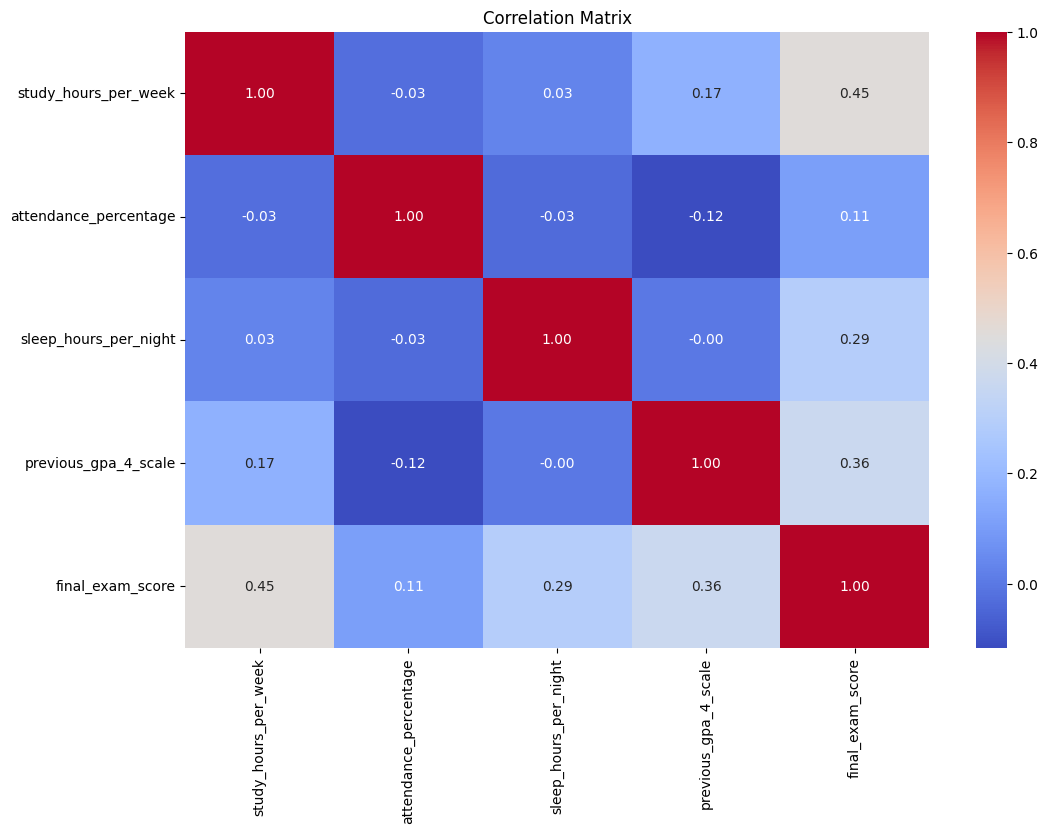

In [30]:
plt.figure(figsize=(12,8))
corr = df.corr(numeric_only=True)

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

In [46]:

from scipy.stats import pearsonr

target = 'final_exam_score'

results = []

for col in numerical_cols:

    if col != target:

        r, p = pearsonr(df[col], df[target])

        results.append({
            'Variable': col,
            'Correlation': r,
            'P-value': p,
            'Significant': 'Yes' if p < 0.05 else 'No'
        })

correlation_results = pd.DataFrame(results)

print(correlation_results.round(4))


                Variable  Correlation  P-value Significant
0   study_hours_per_week       0.4515    0.000         Yes
1  attendance_percentage       0.0976    0.169          No
2  sleep_hours_per_night       0.3001    0.000         Yes
3   previous_gpa_4_scale       0.3665    0.000         Yes


# HYPOTHESIS TESTING

# Welch's Independent Samples T-Test

In [31]:
print("\n========== HYPOTHESIS TESTING ==========")

# Test 1: Internet Access

yes = df.loc[
    df["internet_access"] == "Yes",
    "final_exam_score"
]

no = df.loc[
    df["internet_access"] == "No",
    "final_exam_score"
]

t, p = stats.ttest_ind(
    yes,
    no,
    equal_var=False
)

print("\nInternet Access: Yes vs No")

print(f"T-statistic: {t:.3f}")
print(f"P-value: {p:.4g}")

print(f"Yes Group Mean: {yes.mean():.2f}")
print(f"No Group Mean: {no.mean():.2f}")

if p < 0.05:
    print("Result: Statistically significant difference.")
else:
    print("Result: No statistically significant difference.")


========== HYPOTHESIS TESTING ==========

Internet Access: Yes vs No
T-statistic: 0.454
P-value: 0.6512
Yes Group Mean: 91.11
No Group Mean: 90.47
Result: No statistically significant difference.


# Test 2: Extracurricular Participation

In [32]:
yes_extra = df.loc[
    df["extracurricular_participation"] == "Yes",
    "final_exam_score"
]

no_extra = df.loc[
    df["extracurricular_participation"] == "No",
    "final_exam_score"
]

t2, p2 = stats.ttest_ind(
    yes_extra,
    no_extra,
    equal_var=False
)

print("\nExtracurricular Participation: Yes vs No")

print(f"T-statistic: {t2:.3f}")
print(f"P-value: {p2:.4g}")

print(f"Yes Group Mean: {yes_extra.mean():.2f}")
print(f"No Group Mean: {no_extra.mean():.2f}")

if p2 < 0.05:
    print("Result: Statistically significant difference.")
else:
    print("Result: No statistically significant difference.")


Extracurricular Participation: Yes vs No
T-statistic: -1.186
P-value: 0.2376
Yes Group Mean: 90.11
No Group Mean: 91.46
Result: No statistically significant difference.


In [5]:
df

,student_id,study_hours_per_week,attendance_percentage,sleep_hours_per_night,previous_gpa_4_scale,internet_access,extracurricular_participation,final_exam_score,grade
0,STU001,11.9,75.3,7.1,3.47,Yes,No,100.0,A
1,STU002,13.1,99.8,6.3,2.43,Yes,No,87.2,A
2,STU003,12.9,66.6,7.0,1.86,No,No,95.0,A
3,STU004,11.5,75.2,5.8,2.51,Yes,Yes,85.6,A
4,STU005,15.8,85.9,10.0,2.93,Yes,No,100.0,A
...,...,...,...,...,...,...,...,...,...
195,STU196,18.1,83.5,6.5,3.47,Yes,No,99.9,A
196,STU197,9.6,100.0,5.4,2.72,No,Yes,81.9,A
197,STU198,11.0,80.9,6.0,2.72,Yes,No,93.4,A
198,STU199,9.8,93.9,7.4,2.85,Yes,Yes,87.5,A


# MULTIPLE LINEAR REGRESSION

In [33]:
print("\n========== MULTIPLE LINEAR REGRESSION ==========")


========== MULTIPLE LINEAR REGRESSION ==========


# Independent Variables (X)

In [34]:
X = np.column_stack([

    np.ones(len(df)),

    df["study_hours_per_week"],

    df["attendance_percentage"],

    df["previous_gpa_4_scale"],

    df["sleep_hours_per_night"],

    (df["internet_access"] == "Yes").astype(int),

    (df["extracurricular_participation"] == "Yes").astype(int)

])

# Dependent Variable (Y)

In [35]:
y = df["final_exam_score"].to_numpy()

names = [

    "Intercept",
    "Study Hours/Week",
    "Attendance (%)",
    "Previous GPA",
    "Sleep Hours/Night",
    "Internet Access (Yes=1)",
    "Extracurricular (Yes=1)"

]

In [36]:
# Calculate Regression Coefficients
b = np.linalg.lstsq(
    X,
    y,
    rcond=None
)[0]


# Predicted Values
fitted = X @ b

# Residuals

resid = y - fitted

# R-Squared

ss_res = resid @ resid

ss_tot = np.sum((y - y.mean()) ** 2)

r2 = 1 - (ss_res / ss_tot)

# Adjusted R-Squared

n = len(y)

k = X.shape[1] - 1

adj_r2 = 1 - (
    (1 - r2) * (n - 1) / (n - k - 1)
)

# RMSE

rmse = np.sqrt(np.mean(resid ** 2))

# Standard Error

dfr = n - X.shape[1]

s2 = ss_res / dfr

cov_matrix = s2 * np.linalg.pinv(X.T @ X)

se = np.sqrt(np.diag(cov_matrix))

# T-statistics

t_values = b / se

# P-values

pvals = 2 * stats.t.sf(
    np.abs(t_values),
    dfr
)

print(f"\nR-Squared: {r2:.3f}")

print(f"Adjusted R-Squared: {adj_r2:.3f}")

print(f"RMSE: {rmse:.2f}")

print("\nRegression Coefficients:")

for name, coef, stderr, tval, pval in zip(
    names,
    b,
    se,
    t_values,
    pvals
):

    print(
        f"{name}: "
        f"Coefficient={coef:.3f}, "
        f"SE={stderr:.3f}, "
        f"T={tval:.3f}, "
        f"P={pval:.4g}"
    )


R-Squared: 0.405
Adjusted R-Squared: 0.385
RMSE: 6.07

Regression Coefficients:
Intercept: Coefficient=38.546, SE=5.885, T=6.550, P=5.465e-10
Study Hours/Week: Coefficient=0.862, SE=0.124, T=6.977, P=5.129e-11
Attendance (%): Coefficient=0.122, SE=0.041, T=3.005, P=0.003022
Previous GPA: Coefficient=5.833, SE=1.070, T=5.453, P=1.561e-07
Sleep Hours/Night: Coefficient=2.291, SE=0.468, T=4.896, P=2.114e-06
Internet Access (Yes=1): Coefficient=0.383, SE=1.132, T=0.338, P=0.7355
Extracurricular (Yes=1): Coefficient=-1.486, SE=0.942, T=-1.577, P=0.1164


# SAVE ANALYSIS TABLES

In [37]:
print("\n========== SAVING ANALYSIS TABLES ==========")

# Descriptive Statistics

df[numeric].describe().T.to_csv(
     "descriptive_statistics.csv"
)

# Correlation Matrix

corr_matrix.to_csv(
     "correlation_matrix.csv"
)

# Grade Frequency

grade_frequency.to_csv(
    "grade_frequency.csv"
)

# Regression Results

regression_results = pd.DataFrame({

    "Variable": names,
    "Coefficient": b,
    "Standard_Error": se,
    "T_Statistic": t_values,
    "P_Value": pvals

})

regression_results.to_csv(
    "regression_results.csv",
    index=False
)

print("Analysis tables saved successfully!")


========== SAVING ANALYSIS TABLES ==========
Analysis tables saved successfully!


# DATA VISUALIZATION

In [38]:
# Figure 1: Final Exam Score Distribution

plt.figure(figsize=(8, 5))

plt.hist(
    df["final_exam_score"],
    bins=14,
    edgecolor="black"
)

plt.xlabel("Final Exam Score")

plt.ylabel("Number of Students")

plt.title("Distribution of Final Exam Scores")

plt.tight_layout()

plt.savefig(
   "score_distribution.png",
    dpi=180
)

plt.close()


# Figure 2: Study Hours vs Final Exam Score

plt.figure(figsize=(8, 5))

plt.scatter(
    df["study_hours_per_week"],
    df["final_exam_score"],
    alpha=0.7
)

m, c = np.polyfit(
    df["study_hours_per_week"],
    df["final_exam_score"],
    1
)

xline = np.linspace(
    df["study_hours_per_week"].min(),
    df["study_hours_per_week"].max(),
    100
)

plt.plot(
    xline,
    m * xline + c
)

plt.xlabel("Study Hours per Week")

plt.ylabel("Final Exam Score")

plt.title("Study Hours vs Final Exam Score")

plt.tight_layout()

plt.savefig(
   "study_vs_score.png",
    dpi=180
)

plt.close()


# Figure 3: Correlation Heatmap

plt.figure(figsize=(9, 6))

plt.imshow(
    corr_matrix,
    cmap="coolwarm",
    interpolation="nearest",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(numeric)),
    numeric,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(numeric)),
    numeric
)

plt.title("Student Performance Correlation Heatmap")

plt.tight_layout()

plt.savefig(
   "correlation_heatmap.png",
    dpi=180
)

plt.close()


# Figure 4: Grade Distribution

plt.figure(figsize=(8, 5))

grade_frequency.plot(
    kind="bar",
    edgecolor="black"
)

plt.xlabel("Grade")

plt.ylabel("Number of Students")

plt.title("Student Grade Distribution")

plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "grade_distribution.png",
    dpi=180
)

plt.close()


# Figure 5: Attendance vs Final Exam Score

plt.figure(figsize=(8, 5))

plt.scatter(
    df["attendance_percentage"],
    df["final_exam_score"],
    alpha=0.7
)

plt.xlabel("Attendance Percentage")

plt.ylabel("Final Exam Score")

plt.title("Attendance vs Final Exam Score")

plt.tight_layout()

plt.savefig(
    "attendance_vs_score.png",
    dpi=180
)

plt.close()


# FINAL OUTPUT

In [39]:
print("\n========== ANALYSIS COMPLETED ==========")

print(f"Total Students: {len(df)}")

print(f"Average Final Exam Score: {df['final_exam_score'].mean():.2f}")

print(f"Highest Final Exam Score: {df['final_exam_score'].max():.2f}")

print(f"Lowest Final Exam Score: {df['final_exam_score'].min():.2f}")

print(f"\nAll outputs saved")

print("\nStudent Academic Performance Analysis Completed!")



========== ANALYSIS COMPLETED ==========
Total Students: 193
Average Final Exam Score: 90.98
Highest Final Exam Score: 100.00
Lowest Final Exam Score: 67.30

All outputs saved

Student Academic Performance Analysis Completed!
